# Оптимизаторы 2D: от градиентного спуска к AdamW

Продолжение `Сравнение методов 2D.ipynb` и `Решение задач с двумя параметрами.ipynb`.
Те же двумерные задачи нужны здесь для того, чтобы **наглядно** сравнить шесть методов
первого порядка — те, что лежат в основе обучения нейросетей.

Договорённости:
- градиент **аналитический** (как `backprop` даёт точный градиент, без численной разности);
- **guard убран** — метод не останавливается, если `f` выросла (так и работает реальное обучение);
- пока **без мини-батчей и шума** — это детерминированный спуск по всей функции (SGD добавим позже);
- на каждый случай берём **один общий шаг η** для всех шести методов, чтобы разница шла от метода,
  а не от подгонки шага.

Шесть методов: **GD (постоянный шаг) → Momentum → AdaGrad → RMSProp → Adam → AdamW**.

> Алгоритмы написаны на **чистом Python** (списки и циклы, модуль `math`).
> `numpy` вызывается только в одной ячейке — для отрисовки 3D-поверхности (`matplotlib` там требует массивы);
> `matplotlib` подключён только чтобы рисовать графики.

In [1]:
import math
import warnings
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

warnings.filterwarnings("ignore")


def dist(p, ref):
    '''Евклидово расстояние между двумя точками [x, y].'''
    return math.hypot(p[0] - ref[0], p[1] - ref[1])


def linspace(a, b, n):
    '''n равномерных точек от a до b (включительно) — замена numpy.linspace.'''
    step = (b - a) / (n - 1)
    return [a + i * step for i in range(n)]


def meshgrid(xs, ys):
    '''Сетка: два вложенных списка X и Y (замена numpy.meshgrid).'''
    X = [[x for x in xs] for _ in ys]
    Y = [[y for _ in xs] for y in ys]
    return X, Y


def logspace(a, b, n):
    '''n точек по логарифмической шкале от a до b.'''
    la, lb = math.log10(a), math.log10(b)
    return [10 ** (la + (lb - la) * i / (n - 1)) for i in range(n)]

## 1. Задачи

Пять случаев, каждый показывает свой эффект:

| Случай | Ландшафт | Что показывает |
|:---|:---|:---|
| `par` | изотропный параболоид | эталон: все методы сходятся |
| `3. МНК` | квадратичная, `cond ≈ 27` | вытянутый **овраг**: фикс. шаг зигзагует |
| `9. Температура` | седло `(0;0)` + минимум `(1;1)` | криволинейный путь, роль седла |
| `Розенброк` | банановая долина | **крайний случай**: где постоянный шаг буксует |
| `aniso` | разные масштабы осей, `cond = 1000` | **нестандартный**: Momentum буксует по «плоской» оси, адаптивные нормируют |

Точка — это список `[x, y]`; градиент возвращает список `[gx, gy]`; Гессиан — список списков.

In [2]:
# --- простой параболоид f = x^2 + y^2 ---
def f_par(x):
    return x[0]**2 + x[1]**2
def g_par(x):  #градиент
    return [2*x[0], 2*x[1]]
def h_par(x):  #Гессиан
    return [[2.0, 0.0], [0.0, 2.0]]


# --- 3. МНК: подбор прямой y = k*x + b по пяти точкам ---
POINTS = [(1, 2), (2, 2), (3, 4), (4, 5), (5, 6)]
def f_mnk(x):
    k, b = x
    return sum((k*px + b - py)**2 for px, py in POINTS)
def g_mnk(x):
    k, b = x
    gk = 2*sum(px*(k*px + b - py) for px, py in POINTS)
    gb = 2*sum((k*px + b - py) for px, py in POINTS)
    return [gk, gb]
def h_mnk(x):
    return [[110.0, 30.0], [30.0, 10.0]]


# --- 9. Температура T = x^3 + y^3 - 3xy ---
def f_temp(x):
    return x[0]**3 + x[1]**3 - 3*x[0]*x[1]
def g_temp(x):
    return [3*x[0]**2 - 3*x[1], 3*x[1]**2 - 3*x[0]]
def h_temp(x):
    return [[6*x[0], -3.0], [-3.0, 6*x[1]]]


# --- Розенброк (банановая долина) ---
def f_rosen(x):
    return (1 - x[0])**2 + 100*(x[1] - x[0]**2)**2
def g_rosen(x):
    return [-2*(1 - x[0]) - 400*x[0]*(x[1] - x[0]**2),
            200*(x[1] - x[0]**2)]
def h_rosen(x):
    return [[2 - 400*x[1] + 1200*x[0]**2, -400*x[0]],
            [-400*x[0], 200.0]]


# --- aniso: разные масштабы осей, f = 0.5*(0.001*x^2 + y^2) ---
def f_aniso(x):
    return 0.5 * (0.001*x[0]**2 + x[1]**2)
def g_aniso(x):
    return [0.001*x[0], x[1]]
def h_aniso(x):
    return [[0.001, 0.0], [0.0, 1.0]]


# (имя, f, grad, hess, старт, эталон-минимум, общий шаг η, log-масштаб для графика)
CASES = [
    ("par (параболоид)", f_par,   g_par,   h_par,   [4.0, 3.0], [0.0, 0.0], 0.1,   False),
    ("3. МНК",           f_mnk,   g_mnk,   h_mnk,   [0.5, 0.5], [1.1, 0.5], 0.015, False),
    ("9. Температура",   f_temp,  g_temp,  h_temp,  [0.5, 0.5], [1.0, 1.0], 0.05,  False),
    ("Розенброк",        f_rosen, g_rosen, h_rosen, [0.0, 0.0], [1.0, 1.0], 0.002, True),
    ("aniso (масштабы)", f_aniso, g_aniso, h_aniso, [4.0, 3.0], [0.0, 0.0], 0.1,   False),
]

### Ландшафт `aniso` в 3D

Поверхность **почти не меняется вдоль `x`** и круто растёт вдоль `y` — это и есть «плоская» ось,
из-за которой GD и Momentum буксуют.

> Для 3D-поверхности `matplotlib` требует массивы, поэтому только в этой ячейке вызывается `numpy`;
> все алгоритмы остаются на чистом Python.

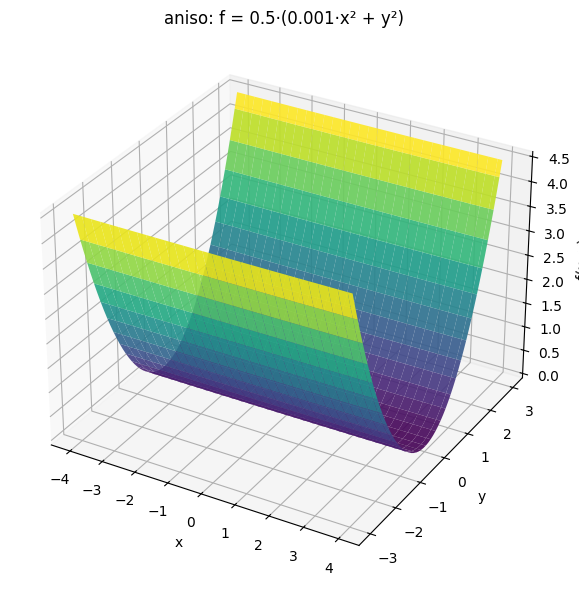

In [3]:
from mpl_toolkits.mplot3d import Axes3D
import numpy as np   # только для отрисовки 3D-поверхности

def surface_3d(f, x_range, y_range, title, n=60, elev=30, azim=-60):
    xs = [x_range[0] + (x_range[1] - x_range[0]) * i / (n - 1) for i in range(n)]
    ys = [y_range[0] + (y_range[1] - y_range[0]) * i / (n - 1) for i in range(n)]
    X, Y = meshgrid(xs, ys)
    Z = [[f([x, y]) for x in xs] for y in ys]
    fig = plt.figure(figsize=(9, 6))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(np.asarray(X), np.asarray(Y), np.asarray(Z),
                    cmap="viridis", linewidth=0, antialiased=True, alpha=0.9)
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("f(x, y)")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

surface_3d(f_aniso, [-4, 4], [-3, 3], "aniso: f = 0.5·(0.001·x² + y²)")

In [4]:
# наибольшее собственное число Гессиана — ориентир для устойчивого шага GD (η < 2/λmax)
def lambda_max(H): 
    tr = H[0][0] + H[1][1]
    det = H[0][0]*H[1][1] - H[0][1]*H[1][0]
    disc = max(tr*tr - 4*det, 0.0)
    return (tr + math.sqrt(disc)) / 2

for name, f, grad, hess, x0, ref, eta, logz in CASES:
    lm = lambda_max(hess(x0))
    start = (round(x0[0], 3), round(x0[1], 3))
    print(f"{name:>18}: старт {start},  λmax={lm:8.3g}, граница GD η<{2/lm:8.4g}, взят η={eta}")

  par (параболоид): старт (4.0, 3.0),  λmax=       2, граница GD η<       1, взят η=0.1
            3. МНК: старт (0.5, 0.5),  λmax=     118, граница GD η<  0.0169, взят η=0.015
    9. Температура: старт (0.5, 0.5),  λmax=       6, граница GD η<  0.3333, взят η=0.05
         Розенброк: старт (0.0, 0.0),  λmax=     200, граница GD η<    0.01, взят η=0.002
  aniso (масштабы): старт (4.0, 3.0),  λmax=       1, граница GD η<       2, взят η=0.1


## 2. Шесть оптимизаторов

Общий скелет, меняется только правило обновления. `ε` — защита от деления на ноль;
`β` (или `β₁`, `β₂`) — коэффициенты сглаживания; `wd` — затухание весов (weight decay).

In [5]:
METHODS = [
    ("gd",       "GD (пост. шаг)"),
    ("momentum", "Momentum"),
    ("adagrad",  "AdaGrad"),
    ("rmsprop",  "RMSProp"),
    ("adam",     "Adam"),
    ("adamw",    "AdamW"),
]

def optimize(method, grad, x0, eta, n_steps,
             b1=0.9, b2=0.999, beta=0.9, eps=1e-8, wd=0.01):
    '''Прогон одного метода. Возвращает историю точек [[x, y], ...].
    Guard отсутствует: метод не останавливается, если f выросла.'''
    x = [float(x0[0]), float(x0[1])]
    m = [0.0, 0.0]   # накопленный импульс
    v = [0.0, 0.0]   # накопленный квадрат градиента
    history = [x[:]]
    for t in range(1, n_steps + 1):
        try:
            g = grad(x)
            if method == "gd":
                x = [x[0] - eta * g[0],
                     x[1] - eta * g[1]]
            elif method == "momentum":
                m = [beta*m[0] + g[0],
                     beta*m[1] + g[1]]
                x = [x[0] - eta * m[0],
                     x[1] - eta * m[1]]
            elif method == "adagrad":
                v = [v[0] + g[0]**2,
                     v[1] + g[1]**2]
                x = [x[0] - eta * g[0] / (math.sqrt(v[0]) + eps),
                     x[1] - eta * g[1] / (math.sqrt(v[1]) + eps)]
            elif method == "rmsprop":
                v = [beta*v[0] + (1 - beta)*g[0]**2,
                     beta*v[1] + (1 - beta)*g[1]**2]
                x = [x[0] - eta * g[0] / (math.sqrt(v[0]) + eps),
                     x[1] - eta * g[1] / (math.sqrt(v[1]) + eps)]
            elif method == "adam":
                m = [b1*m[0] + (1 - b1)*g[0],
                     b1*m[1] + (1 - b1)*g[1]]
                v = [b2*v[0] + (1 - b2)*g[0]**2,
                     b2*v[1] + (1 - b2)*g[1]**2]
                mh = [m[0] / (1 - b1**t), m[1] / (1 - b1**t)]
                vh = [v[0] / (1 - b2**t), v[1] / (1 - b2**t)]
                x = [x[0] - eta * mh[0] / (math.sqrt(vh[0]) + eps),
                     x[1] - eta * mh[1] / (math.sqrt(vh[1]) + eps)]
            elif method == "adamw":
                m = [b1*m[0] + (1 - b1)*g[0],
                     b1*m[1] + (1 - b1)*g[1]]
                v = [b2*v[0] + (1 - b2)*g[0]**2,
                     b2*v[1] + (1 - b2)*g[1]**2]
                mh = [m[0] / (1 - b1**t), m[1] / (1 - b1**t)]
                vh = [v[0] / (1 - b2**t), v[1] / (1 - b2**t)]
                x = [x[0] - eta * (mh[0] / (math.sqrt(vh[0]) + eps) + wd*x[0]),
                     x[1] - eta * (mh[1] / (math.sqrt(vh[1]) + eps) + wd*x[1])]
        except (OverflowError, ZeroDivisionError, ValueError):
            break   # чистый Python при расхождении бросает OverflowError, а не даёт inf
        history.append(x[:])
        if not (math.isfinite(x[0]) and math.isfinite(x[1])):
            break
    return history

## 3. Результаты: шаги до сходимости

Считаем, что метод **сошёлся**, если попал в `0.05` от эталонного минимума.
`×` — не сошлось за отведённые шаги либо расхождение (значения ушли в бесконечность).

In [6]:
ETA = {c[0]: c[6] for c in CASES}
MAX_ITER = 5000
TOL = 0.05

def finite(hist):
    return all(math.isfinite(p[0]) and math.isfinite(p[1]) for p in hist)

def run_case(method, grad, x0, ref, eta, max_iter=MAX_ITER, tol=TOL):
    hist = optimize(method, grad, x0, eta, max_iter)
    if not finite(hist):
        return hist, None, "расхождение"
    ds = [dist(p, ref) for p in hist]
    inside = [i for i, d in enumerate(ds) if d < tol]
    if inside:
        return hist[:inside[0] + 1], inside[0], f"{min(ds):.4f}"
    return hist, None, f"× (мин. {min(ds):.3f})"

TRAJ = {}
STEPS = {}
lines = [
    "| Случай | Метод | Шагов до сходимости | Мин. ρ до эталона |",
    "|:---|:---|:---:|:---:|",
]
for name, f, grad, hess, x0, ref, eta, logz in CASES:
    for method, label in METHODS:
        hist, steps, d = run_case(method, grad, x0, ref, eta)
        TRAJ[(name, method)] = hist
        STEPS[(name, method)] = steps
        s = "×" if steps is None else str(steps)
        lines.append(f"| {name} | {label} | {s} | {d} |")
display(Markdown("\n".join(lines)))

| Случай | Метод | Шагов до сходимости | Мин. ρ до эталона |
|:---|:---|:---:|:---:|
| par (параболоид) | GD (пост. шаг) | 21 | 0.0000 |
| par (параболоид) | Momentum | 10 | 0.0000 |
| par (параболоид) | AdaGrad | 1675 | 0.0000 |
| par (параболоид) | RMSProp | 54 | 0.0000 |
| par (параболоид) | Adam | 94 | 0.0000 |
| par (параболоид) | AdamW | 92 | 0.0000 |
| 3. МНК | GD (пост. шаг) | 46 | 0.0000 |
| 3. МНК | Momentum | 11 | 0.0000 |
| 3. МНК | AdaGrad | × | × (мин. 0.247) |
| 3. МНК | RMSProp | 100 | 0.0017 |
| 3. МНК | Adam | 426 | 0.0000 |
| 3. МНК | AdamW | 445 | 0.0006 |
| 9. Температура | GD (пост. шаг) | 22 | 0.0000 |
| 9. Температура | Momentum | 21 | 0.0000 |
| 9. Температура | AdaGrad | 52 | 0.0000 |
| 9. Температура | RMSProp | 6 | 0.0000 |
| 9. Температура | Adam | 10 | 0.0000 |
| 9. Температура | AdamW | 10 | 0.0000 |
| Розенброк | GD (пост. шаг) | 3290 | 0.0125 |
| Розенброк | Momentum | 289 | 0.0000 |
| Розенброк | AdaGrad | × | × (мин. 1.185) |
| Розенброк | RMSProp | 2344 | 0.0040 |
| Розенброк | Adam | 1079 | 0.0000 |
| Розенброк | AdamW | 1113 | 0.0012 |
| aniso (масштабы) | GD (пост. шаг) | × | × (мин. 2.426) |
| aniso (масштабы) | Momentum | 4350 | 0.0259 |
| aniso (масштабы) | AdaGrad | 1675 | 0.0000 |
| aniso (масштабы) | RMSProp | 54 | 0.0000 |
| aniso (масштабы) | Adam | 94 | 0.0000 |
| aniso (масштабы) | AdamW | 92 | 0.0000 |

### Вывод по таблице

Сравнение методов показывает, что на простых задачах (par) Adam, AdamW, MRSProp в разы медленнее GD (различия в 4.5 раз GD против Adam для параболоида). На вытянутых оврагах (МНК) Adam в 38.7 раз медленнее Momentum. Отсюда следует, что универсальность не всегда соответствует оптимальности, для выбора наиболее оптимального метода следует смотреть на ланшафт функции. Это подтверждает и тест aniso, где лучшие результаты показывают RMSProp, Adam и AdamW, а momentum значительно уступает им по количеству сделанных шагов и точности.

## 4. Траектории на линиях уровня

Те же прогоны, нарисованные поверх линий уровня `f(x, y)` — видно **форму** пути,
а не только число шагов. Для каждого случая: по одной панели на метод и общая панель
«все вместе». Внутри случая у всех методов один и тот же шаг η.

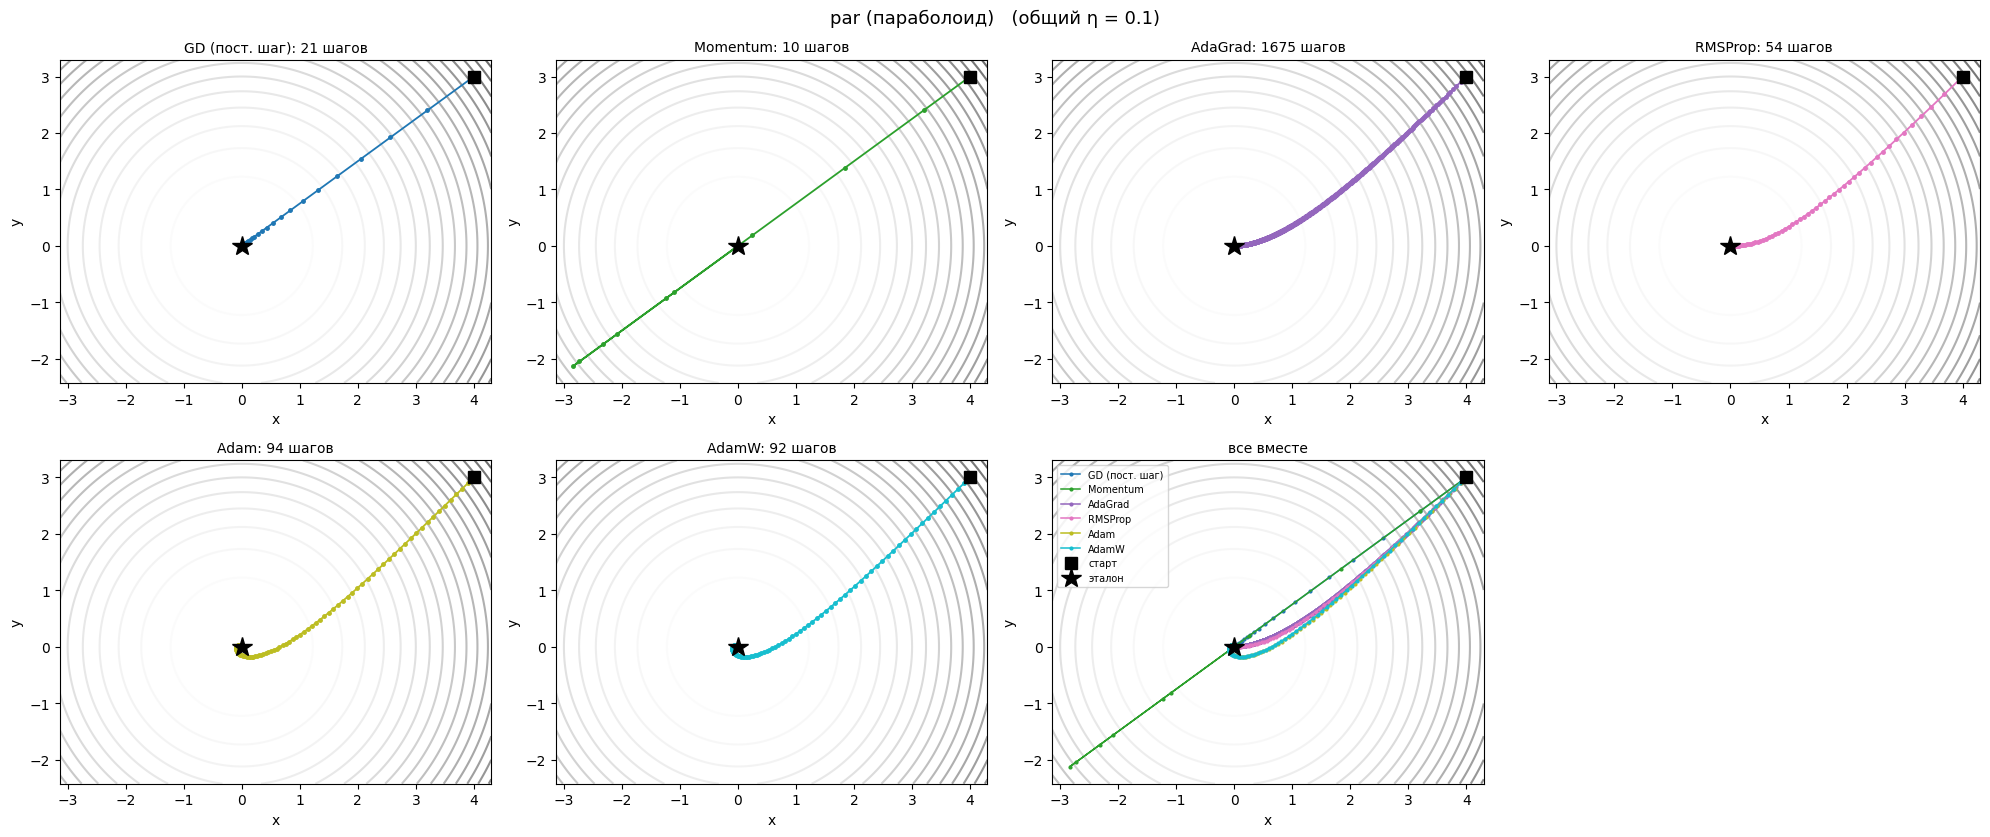

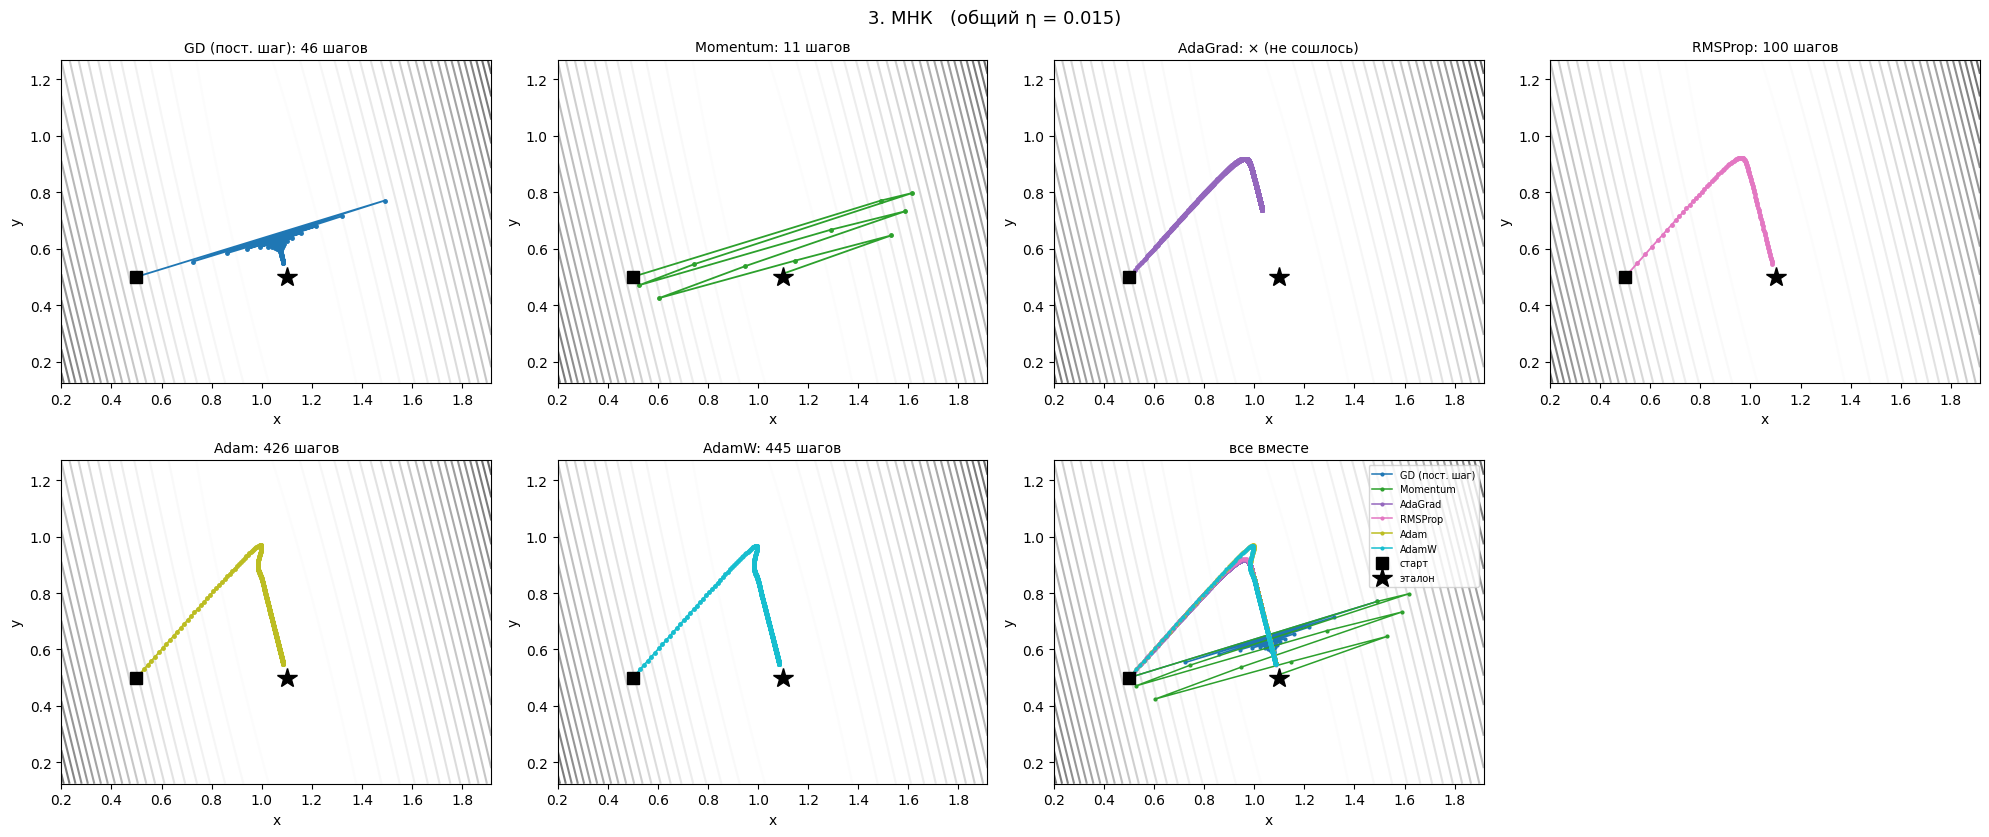

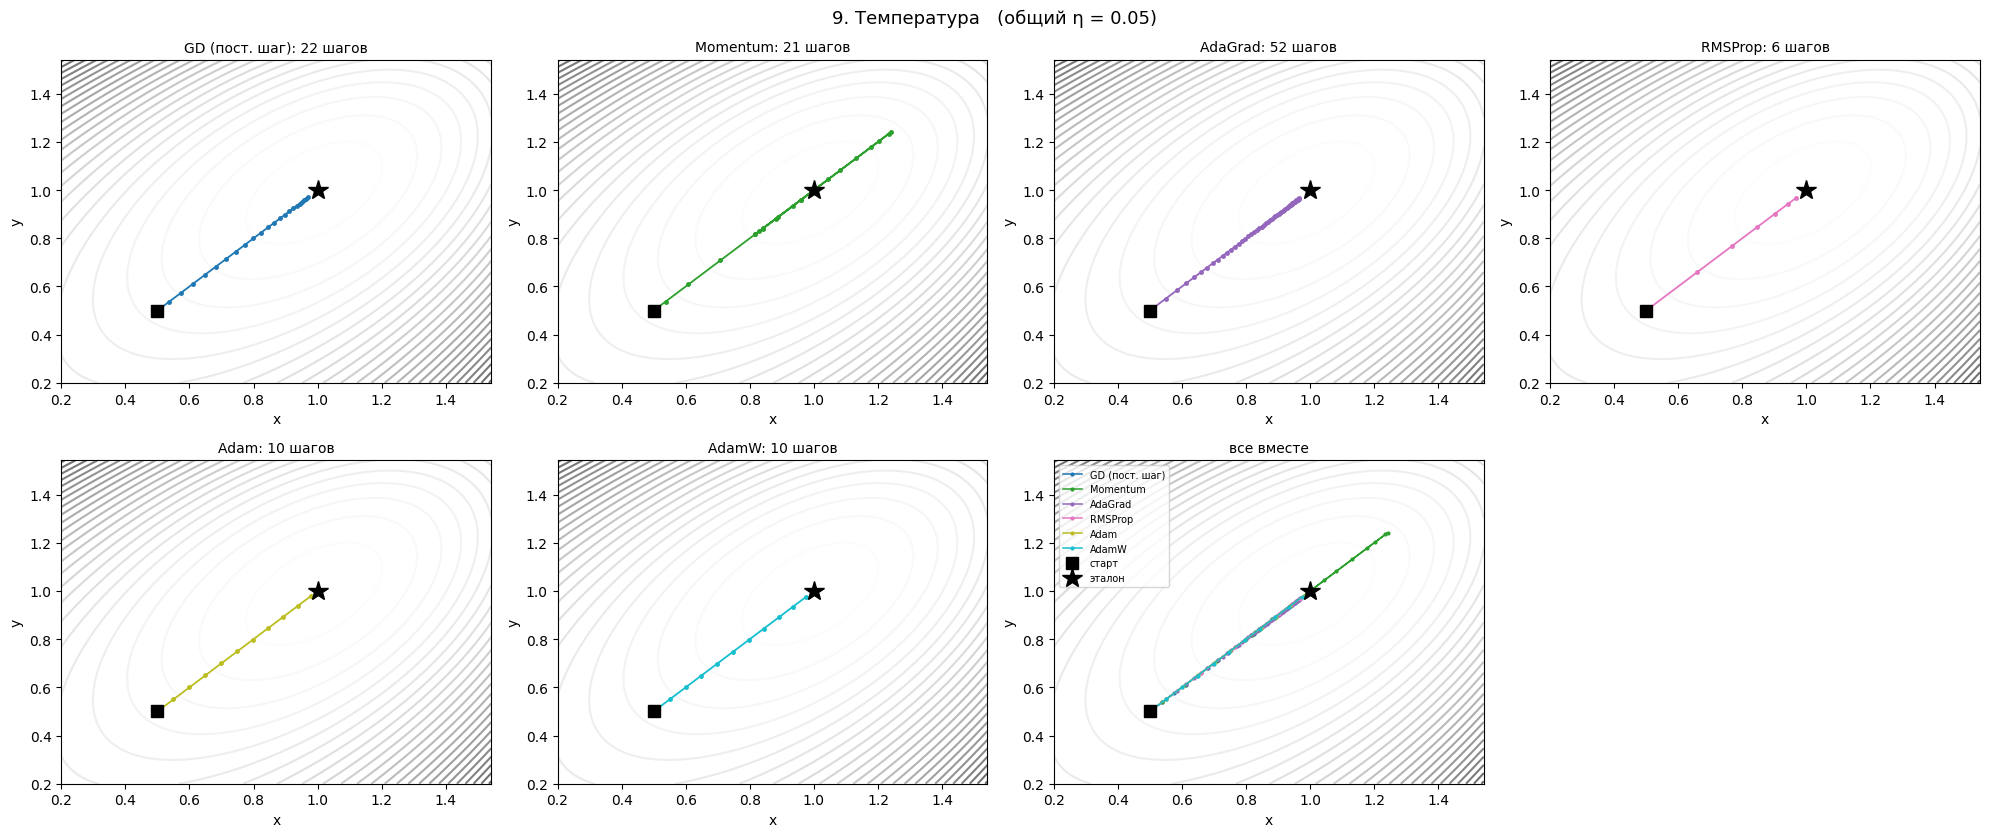

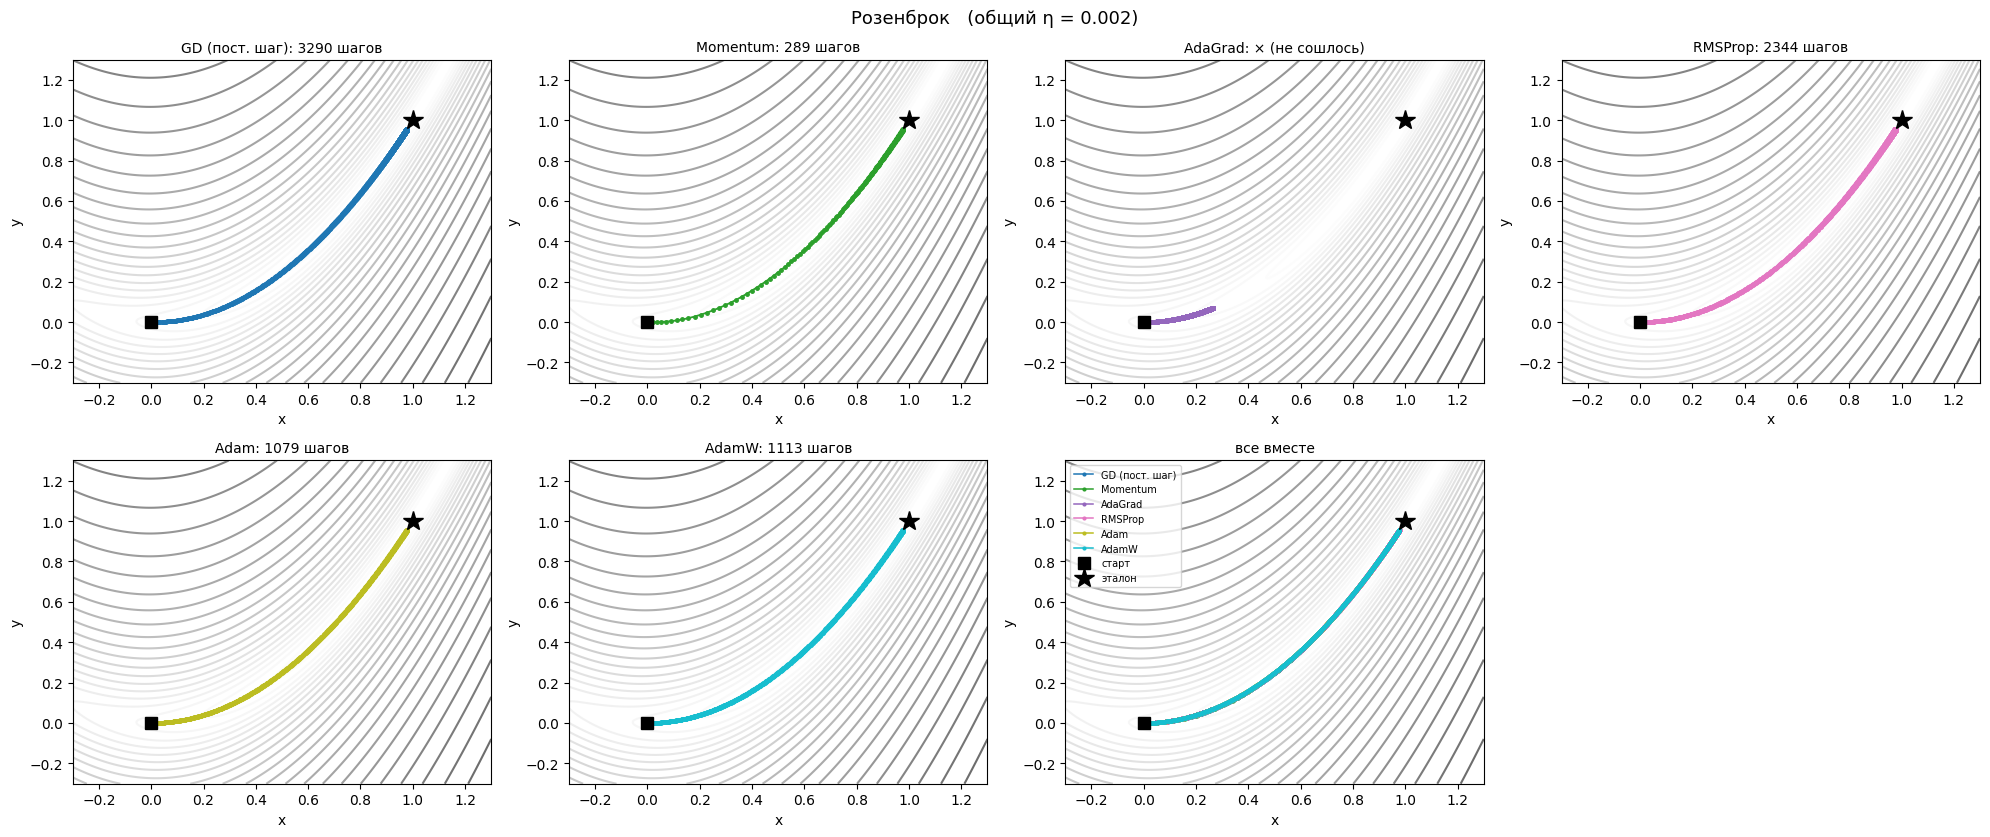

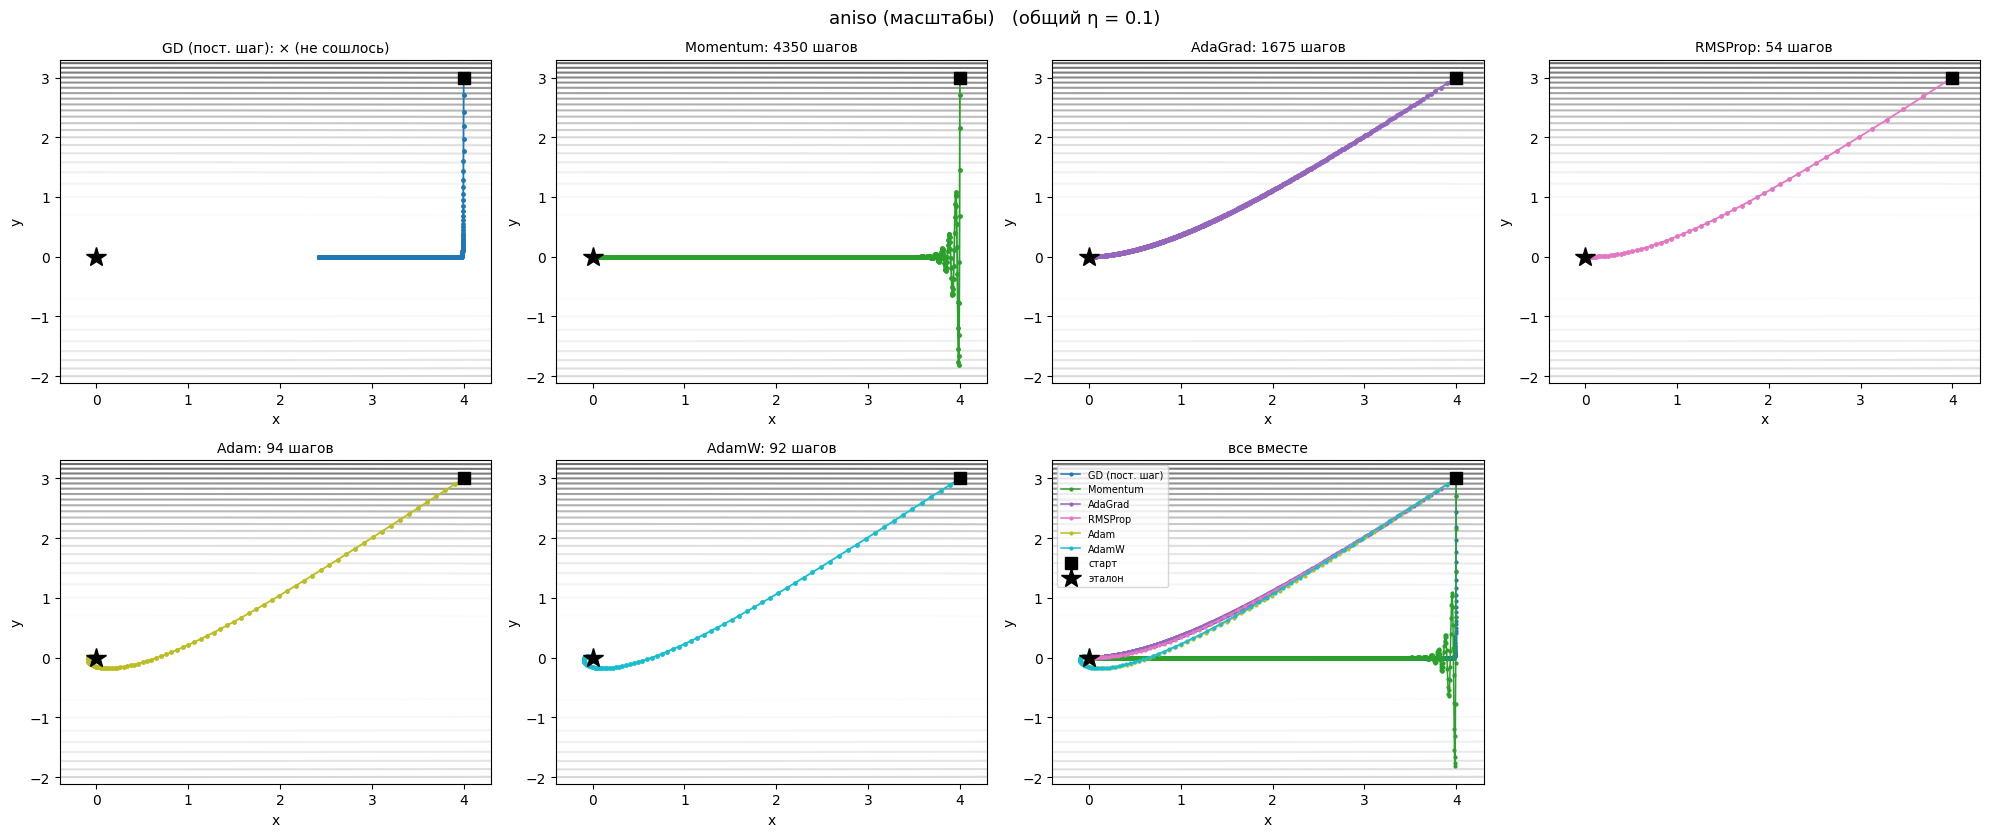

In [7]:
def plot_case(name, f, x0, ref, logz=False):
    allp = [p for m, _ in METHODS for p in TRAJ[(name, m)]] + [x0, ref]
    allp = [p for p in allp if math.isfinite(p[0]) and math.isfinite(p[1])]
    pad = 0.3
    xa, xb = min(p[0] for p in allp) - pad, max(p[0] for p in allp) + pad
    ya, yb = min(p[1] for p in allp) - pad, max(p[1] for p in allp) + pad
    xs = linspace(xa, xb, 250)
    ys = linspace(ya, yb, 250)
    X, Y = meshgrid(xs, ys)
    Z = [[(math.log1p(f([x, y])) if logz else f([x, y])) for x in xs] for y in ys]

    fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
    axes = axes.flatten()
    colors = plt.cm.tab10([i / (len(METHODS) - 1) for i in range(len(METHODS))])
    for k, ((method, label), color) in enumerate(zip(METHODS, colors)):
        ax = axes[k]
        ax.contour(X, Y, Z, levels=25, cmap="Greys", alpha=0.6)
        h = TRAJ[(name, method)]
        ax.plot([p[0] for p in h], [p[1] for p in h], "-o", color=color, ms=2.5, lw=1.3)
        ax.plot(x0[0], x0[1], "ks", ms=8)
        ax.plot(ref[0], ref[1], "k*", ms=15)
        st = STEPS[(name, method)]
        title = f"{label}: {st} шагов" if st is not None else f"{label}: × (не сошлось)"
        ax.set_title(title, fontsize=10)
        ax.set_xlim(xa, xb); ax.set_ylim(ya, yb)
        ax.set_xlabel("x"); ax.set_ylabel("y")
    ax = axes[len(METHODS)]
    ax.contour(X, Y, Z, levels=25, cmap="Greys", alpha=0.6)
    for (method, label), color in zip(METHODS, colors):
        h = TRAJ[(name, method)]
        ax.plot([p[0] for p in h], [p[1] for p in h], "-o", color=color, ms=2, lw=1.1, label=label)
    ax.plot(x0[0], x0[1], "ks", ms=8, label="старт")
    ax.plot(ref[0], ref[1], "k*", ms=15, label="эталон")
    ax.set_title("все вместе", fontsize=10)
    ax.set_xlim(xa, xb); ax.set_ylim(ya, yb)
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.legend(fontsize=7)
    axes[len(METHODS) + 1].axis("off")
    fig.suptitle(f"{name}   (общий η = {ETA[name]})", fontsize=13)
    plt.tight_layout()
    plt.show()

for name, f, grad, hess, x0, ref, eta, logz in CASES:
    plot_case(name, f, x0, ref, logz)

### Вывод по траекториям

**Параболоид:** представляется наиболее базовым тестом, который проходят все методы, различается только скорость сходимости. По количеству сделанных шагов(наименьшее) выигрывает momentum за счет инерции. 

**МНК:** GD скачет поперек оврага. AdaGrad не сходится. Momentum уменьшает зигзаги по сравнению с GD, на этом тестовом случает сходится быстрее всего. RMSProp и Adam убирают зигзаги вдоль крутого направления, ускоряя движение вдоль пологого, что приводит к прямой сходимости.

**Температура:** В тесте старт осуществляется из токи [0.5, 0.5], что позволяет найти минимум не застряв в седловой точке. GD и AdaGrad замедляются вблизи седла, так как градиент стремится к нулю. Momentum, MRSProp, Adam, AdamW успешно "проскакивают" седловую точку благодаря накопленной инерции, быстрее достигая минимума. Наилучший результат по количеству шагов у MRSProp.

**Розенброк:** GD (наиболее количество шагов) и  AdaGrad(не сходится, из-за накопления больших квадратов градиентов на крутых стенках долины движение вдоль дна долины практически останавливается) показали наихудшие результаты. RMSProp успешно решает проблему AdaGrad и доходит до минимума, но затрачивает значительно больше шагов чем (Adam, AdamW и Momentum). Adam и AdamW эффективно справляюся в тестом, достигнув минимума. Лучший результат по колчиеству шагов показал Momentum.

**asino:** GD не сходится; momentum сходится, но делает значительно большее количество шагов чем адаптивные методы по причине затухания инерции. По количеству сделанных шагов преимущество имеет MRSProp; Adam и AdamW также эффективно достигают минимума. 



## 5. Устойчивость к выбору шага η

Прогоняем **каждый метод много раз**, каждый раз с другим шагом η (по логарифмической сетке).
В клетке — число шагов до сходимости, `×` — не сошлось / расхождение.
Читается так: у GD рабочее окно η **узкое**, у адаптивных методов — **широкое**.

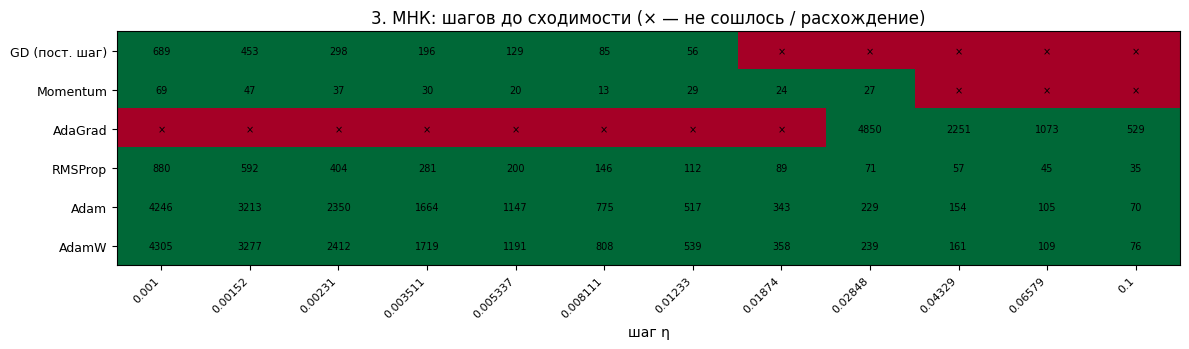

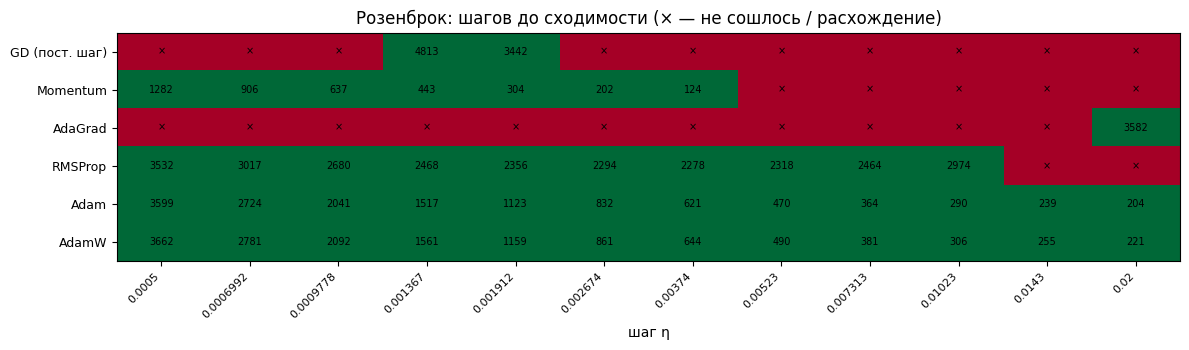

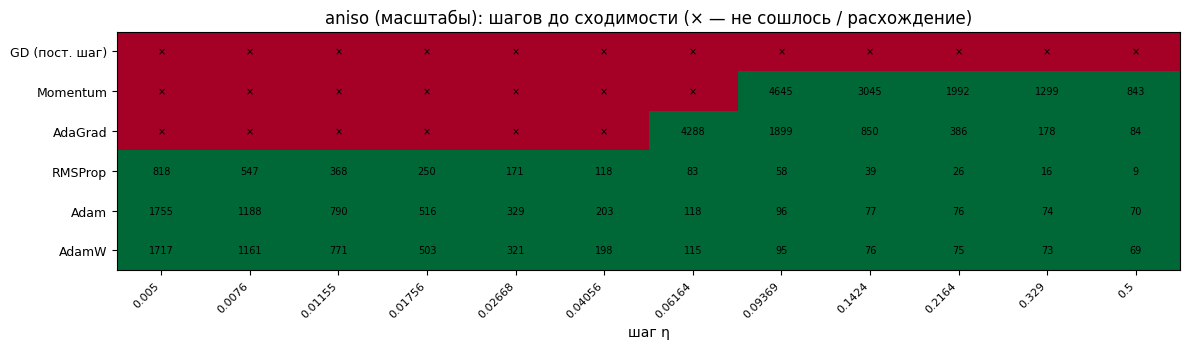

In [8]:
def robustness(case_name, etas, max_iter=MAX_ITER, tol=TOL):
    case = next(c for c in CASES if c[0] == case_name)
    _, f, grad, hess, x0, ref, eta0, logz = case
    ok = [[0.0] * len(etas) for _ in METHODS]
    steps = [[-1] * len(etas) for _ in METHODS]
    for i, (method, label) in enumerate(METHODS):
        for j, e in enumerate(etas):
            hist = optimize(method, grad, x0, e, max_iter)
            if not finite(hist):
                continue
            ds = [dist(p, ref) for p in hist]
            inside = [t for t, d in enumerate(ds) if d < tol]
            if inside:
                ok[i][j] = 1.0
                steps[i][j] = inside[0]
    return ok, steps

def plot_robustness(case_name, etas):
    ok, steps = robustness(case_name, etas)
    fig, ax = plt.subplots(figsize=(12, 3.6))
    ax.imshow(ok, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(etas)))
    ax.set_xticklabels([f"{e:.4g}" for e in etas], rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(METHODS)))
    ax.set_yticklabels([label for _, label in METHODS], fontsize=9)
    for i in range(len(METHODS)):
        for j in range(len(etas)):
            txt = "×" if steps[i][j] < 0 else str(steps[i][j])
            ax.text(j, i, txt, ha="center", va="center", fontsize=7)
    ax.set_xlabel("шаг η")
    ax.set_title(f"{case_name}: шагов до сходимости (× — не сошлось / расхождение)")
    plt.tight_layout()
    plt.show()

plot_robustness("3. МНК", logspace(0.001, 0.1, 12))
plot_robustness("Розенброк", logspace(0.0005, 0.02, 12))
plot_robustness("aniso (масштабы)", logspace(0.005, 0.5, 12))

### Почему RMSProp: эффективный шаг во времени

У AdaGrad знаменатель `√v` — это **накопленная сумма** квадратов градиентов, она только растёт.
Поэтому эффективный шаг `η/√v` со временем **затухает**. RMSProp заменяет сумму на
**скользящее среднее**, и шаг **стабилизируется**. На графике — норма шага `‖Δ_t‖` на задаче `3. МНК`.

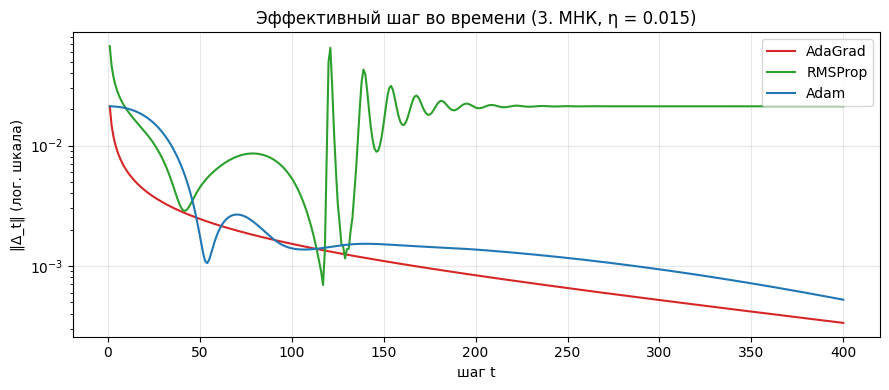

In [9]:
name_step = "3. МНК"
_, f_s, grad_s, hess_s, x0_s, ref_s, eta_s, logz_s = next(c for c in CASES if c[0] == name_step)
N_STEP = 400

def step_norms(kind, grad, x0, eta, n):
    """Норма фактического шага ‖Δ_t‖ на каждом такте."""
    x = [float(x0[0]), float(x0[1])]
    m = [0.0, 0.0]
    v = [0.0, 0.0]
    out = []
    for t in range(1, n + 1):
        g = grad(x)
        if kind == "adagrad":
            v = [v[0] + g[0]**2, v[1] + g[1]**2]
            step = [eta * g[0] / (math.sqrt(v[0]) + 1e-8),
                    eta * g[1] / (math.sqrt(v[1]) + 1e-8)]
        elif kind == "rmsprop":
            v = [0.9*v[0] + 0.1*g[0]**2, 0.9*v[1] + 0.1*g[1]**2]
            step = [eta * g[0] / (math.sqrt(v[0]) + 1e-8),
                    eta * g[1] / (math.sqrt(v[1]) + 1e-8)]
        elif kind == "adam":
            m = [0.9*m[0] + 0.1*g[0], 0.9*m[1] + 0.1*g[1]]
            v = [0.999*v[0] + 0.001*g[0]**2, 0.999*v[1] + 0.001*g[1]**2]
            mh = [m[0] / (1 - 0.9**t), m[1] / (1 - 0.9**t)]
            vh = [v[0] / (1 - 0.999**t), v[1] / (1 - 0.999**t)]
            step = [eta * mh[0] / (math.sqrt(vh[0]) + 1e-8),
                    eta * mh[1] / (math.sqrt(vh[1]) + 1e-8)]
        x = [x[0] - step[0], x[1] - step[1]]
        out.append(math.hypot(step[0], step[1]))
    return out

plt.figure(figsize=(9, 4))
for kind, label, color in [("adagrad", "AdaGrad", "#d62728"),
                           ("rmsprop", "RMSProp", "#2ca02c"),
                           ("adam", "Adam", "#1f77b4")]:
    s = step_norms(kind, grad_s, x0_s, eta_s, N_STEP)
    plt.plot(range(1, N_STEP + 1), s, color=color, label=label)
plt.yscale("log")
plt.xlabel("шаг t"); plt.ylabel("‖Δ_t‖ (лог. шкала)")
plt.title(f"Эффективный шаг во времени ({name_step}, η = {eta_s})")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### Вывод по разделу 5 (сетка η и эффективный шаг)

GD: Крайне чувствителен. При шаге чуть выше порога (например, >0.0169 для МНК) происходит расходимость. При малом шаге сходимость есть, но требует сотен/тысяч шагов.

Momentum: Расширяет рабочее окно по сравнению с GD, но при слишком большом шаге наблюдается расходимость, может перскочить через минимум. 

AdaGrad: Устойчив к большим начальным размерам шага, но на задачах вроде Розенброка перестает обновляться 

RMSProp, Adam, AdamW: Значительно более устойчивы к выбору размера шага (на МНК от 1*10-3 до 1*10-1, разница в 100 раз)

## 6. Отдельный случай: старт ровно в седле

У функции `T = x³ + y³ − 3xy` в точке `(0; 0)` седло и **градиент равен нулю**.
Спуск по градиенту там не делает ни шага — это ограничение всех пяти методов сразу.

In [10]:
x_saddle = [0.0, 0.0]
print("Старт ровно в (0; 0), по 100 шагов каждому методу:")
for method, label in METHODS:
    hist = optimize(method, g_temp, x_saddle, ETA["9. Температура"], 100)
    shift = dist(hist[-1], x_saddle)
    print(f"  {label:>16}: смещение = {shift:.2e}, итог = {hist[-1]}")

Старт ровно в (0; 0), по 100 шагов каждому методу:
    GD (пост. шаг): смещение = 0.00e+00, итог = [0.0, 0.0]
          Momentum: смещение = 0.00e+00, итог = [0.0, 0.0]
           AdaGrad: смещение = 0.00e+00, итог = [0.0, 0.0]
           RMSProp: смещение = 0.00e+00, итог = [0.0, 0.0]
              Adam: смещение = 0.00e+00, итог = [0.0, 0.0]
             AdamW: смещение = 0.00e+00, итог = [0.0, 0.0]


**Вывод:** При старте ровно в точке (0.0, 0.0) все методы (GD, Momentum, AdaGrad, RMSProp, Adam, AdamW) показывают смещение 0.00e+00 и остаются в точке [0.0, 0.0], поскольку градиент в седловой точке равен нулю, алгоритм останавливается.

## 7. Нестандартные случаи

До сих пор все задачи были **статичными, гладкими и одномасштабными** — в таких условиях
Momentum действительно часто выигрывает. Ниже четыре ситуации, которые ломают эти допущения.
Для них нужна другая механика (шум, время, локальные минимумы), поэтому это отдельный блок.

| Случай | Что ломает | Что проверяем |
|:---|:---|:---|
| 7.1 Шум в градиенте | детерминированность | кто устойчив к шуму |
| 7.2 Движущийся минимум | стационарность | кто успевает за движущейся целью |
| 7.3 Локальные минимумы | выпуклость | кто выберется из мелкой ямы |
| 7.4 Плато + узкая яма | равномерность кривизны | кто попадёт в узкую глубокую яму |

In [11]:
import random

def run_dynamic(method, grad_t, x0, eta, n, noise=0.0, seed=0,
                b1=0.9, b2=0.999, beta=0.9, eps=1e-8, wd=0.01):
    # grad_t(x, t) -> [gx, gy]; noise — гауссов шум (эмуляция мини-батча)
    rng = random.Random(seed)
    x = [float(x0[0]), float(x0[1])]
    m = [0.0, 0.0]
    v = [0.0, 0.0]
    hist = [x[:]]
    for t in range(1, n + 1):
        try:
            g = grad_t(x, t)
            if noise:
                g = [g[0] + rng.gauss(0.0, noise), g[1] + rng.gauss(0.0, noise)]
            if method == "gd":
                x = [x[0] - eta*g[0], x[1] - eta*g[1]]
            elif method == "momentum":
                m = [beta*m[0] + g[0], beta*m[1] + g[1]]
                x = [x[0] - eta*m[0], x[1] - eta*m[1]]
            elif method == "adagrad":
                v = [v[0] + g[0]**2, v[1] + g[1]**2]
                x = [x[0] - eta*g[0]/(math.sqrt(v[0]) + eps),
                     x[1] - eta*g[1]/(math.sqrt(v[1]) + eps)]
            elif method == "rmsprop":
                v = [beta*v[0] + (1-beta)*g[0]**2, beta*v[1] + (1-beta)*g[1]**2]
                x = [x[0] - eta*g[0]/(math.sqrt(v[0]) + eps),
                     x[1] - eta*g[1]/(math.sqrt(v[1]) + eps)]
            elif method == "adam":
                m = [b1*m[0] + (1-b1)*g[0], b1*m[1] + (1-b1)*g[1]]
                v = [b2*v[0] + (1-b2)*g[0]**2, b2*v[1] + (1-b2)*g[1]**2]
                x = [x[0] - eta*(m[0]/(1-b1**t))/(math.sqrt(v[0]/(1-b2**t)) + eps),
                     x[1] - eta*(m[1]/(1-b1**t))/(math.sqrt(v[1]/(1-b2**t)) + eps)]
            elif method == "adamw":
                m = [b1*m[0] + (1-b1)*g[0], b1*m[1] + (1-b1)*g[1]]
                v = [b2*v[0] + (1-b2)*g[0]**2, b2*v[1] + (1-b2)*g[1]**2]
                x = [x[0] - eta*((m[0]/(1-b1**t))/(math.sqrt(v[0]/(1-b2**t)) + eps) + wd*x[0]),
                     x[1] - eta*((m[1]/(1-b1**t))/(math.sqrt(v[1]/(1-b2**t)) + eps) + wd*x[1])]
        except (OverflowError, ZeroDivisionError, ValueError):
            break
        hist.append(x[:])
        if not (math.isfinite(x[0]) and math.isfinite(x[1])):
            break
    return hist

### 7.1. Шум в градиенте

Эмулируем мини-батч: к каждому градиенту добавляем гауссов шум `σ = 1.0`.
Ошибку меряем как среднее расстояние до минимума на последних 200 шагах (по 8 случайным зёрнам).

| Метод | Средняя ошибка (последние 200 шагов) |
|:---|:---:|
| GD (пост. шаг) | 0.1402 |
| Momentum | 0.4909 |
| AdaGrad | 0.8804 |
| RMSProp | 0.1347 |
| Adam | 0.1263 |
| AdamW | 0.1259 |

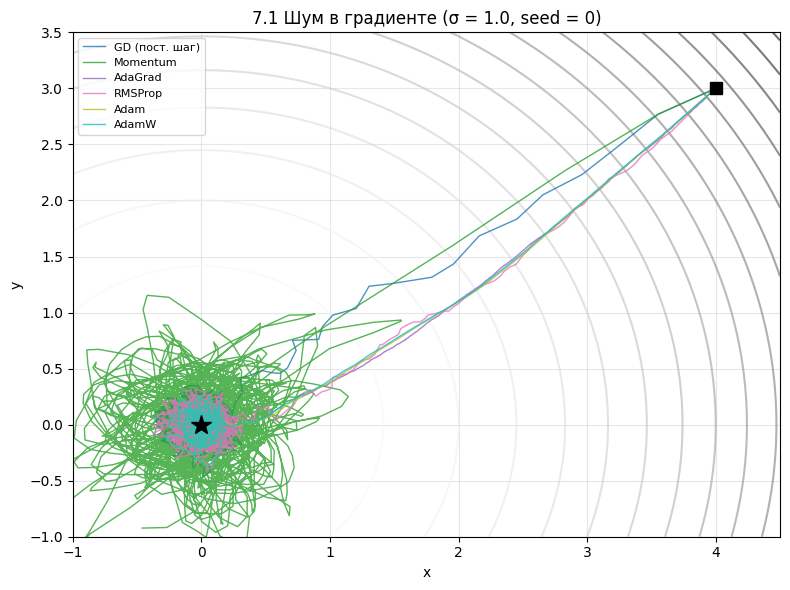

In [12]:
def grad_par_t(x, t):
    return g_par(x)

SIGMA = 1.0
ETA_N = 0.05
N_N = 2000
SEEDS = range(8)

lines = ["| Метод | Средняя ошибка (последние 200 шагов) |", "|:---|:---:|"]
noise_hist = {}
for method, label in METHODS:
    errs = []
    for seed in SEEDS:
        h = run_dynamic(method, grad_par_t, [4.0, 3.0], ETA_N, N_N, noise=SIGMA, seed=seed)
        tail = h[-200:]
        errs.append(sum(dist(p, [0.0, 0.0]) for p in tail) / len(tail))
    noise_hist[method] = run_dynamic(method, grad_par_t, [4.0, 3.0], ETA_N, N_N, noise=SIGMA, seed=0)
    lines.append(f"| {label} | {sum(errs)/len(errs):.4f} |")
display(Markdown("\n".join(lines)))

xs = linspace(-1.0, 4.5, 200); ys = linspace(-1.0, 3.5, 200)
X, Y = meshgrid(xs, ys)
Z = [[f_par([x, y]) for x in xs] for y in ys]
plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z, levels=20, cmap="Greys", alpha=0.6)
colors = plt.cm.tab10([i / (len(METHODS) - 1) for i in range(len(METHODS))])
for (method, label), color in zip(METHODS, colors):
    h = noise_hist[method]
    plt.plot([p[0] for p in h], [p[1] for p in h], "-", color=color, lw=1.0, alpha=0.8, label=label)
plt.plot(4, 3, "ks", ms=8); plt.plot(0, 0, "k*", ms=15)
plt.xlim(-1, 4.5); plt.ylim(-1, 3.5)
plt.xlabel("x"); plt.ylabel("y")
plt.title("7.1 Шум в градиенте (σ = 1.0, seed = 0)")
plt.legend(fontsize=8); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 7.2. Движущийся минимум

Цель — квадратичная функция, центр которой плавно смещается во времени:
`c(t) = (2·sin(t/40), 1.5·sin(t/55 + 1))`. Ошибка — среднее расстояние до **текущего** центра
на последних 800 шагах.

| Метод | Средняя ошибка слежения (последние 800 шагов) |
|:---|:---:|
| GD (пост. шаг) | 0.1488 |
| Momentum | 0.0191 |
| AdaGrad | 1.7049 |
| RMSProp | 0.0689 |
| Adam | 0.0340 |
| AdamW | 0.0340 |

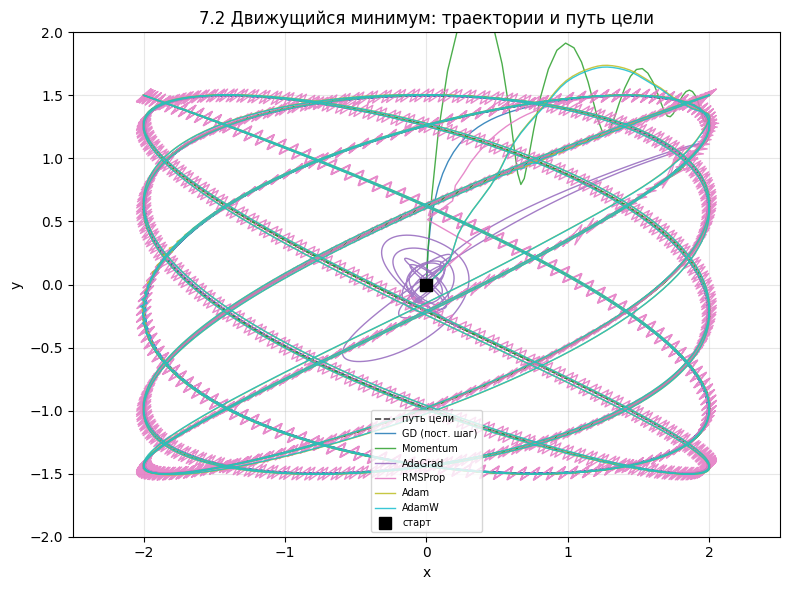

In [13]:
def center(t):
    return (2.0*math.sin(t/40.0), 1.5*math.sin(t/55.0 + 1.0))

def grad_ns(x, t):
    cx, cy = center(t)
    return [2*(x[0] - cx), 2*(x[1] - cy)]

ETA_S = 0.1
N_S = 3000
W_S = 800

lines = ["| Метод | Средняя ошибка слежения (последние 800 шагов) |", "|:---|:---:|"]
ns_hist = {}
for method, label in METHODS:
    h = run_dynamic(method, grad_ns, [0.0, 0.0], ETA_S, N_S)
    errs = [dist(h[i], list(center(i))) for i in range(len(h) - W_S, len(h))]
    ns_hist[method] = h
    lines.append(f"| {label} | {sum(errs)/len(errs):.4f} |")
display(Markdown("\n".join(lines)))

plt.figure(figsize=(8, 6))
colors = plt.cm.tab10([i / (len(METHODS) - 1) for i in range(len(METHODS))])
cx_path = [center(t)[0] for t in range(N_S + 1)]
cy_path = [center(t)[1] for t in range(N_S + 1)]
plt.plot(cx_path, cy_path, "k--", lw=1.2, alpha=0.7, label="путь цели")
for (method, label), color in zip(METHODS, colors):
    h = ns_hist[method]
    plt.plot([p[0] for p in h], [p[1] for p in h], "-", color=color, lw=1.0, alpha=0.85, label=label)
plt.plot(0, 0, "ks", ms=8, label="старт")
plt.xlim(-2.5, 2.5); plt.ylim(-2.0, 2.0)
plt.xlabel("x"); plt.ylabel("y")
plt.title("7.2 Движущийся минимум: траектории и путь цели")
plt.legend(fontsize=7); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Вывод:** RMSProp и Adam/AdamW являются наиболее предпочтительными, так как они постоянно адаптируются и могут "преследовать" смещающийся минимум

### 7.3. Локальные минимумы

Функция `f = (x² − 1)² + 0.3·x + y²` имеет **мелкий** минимум справа и **глубокий** слева.
Старт — в мелком. Без шума все методы, скорее всего, останутся в нём: это общее ограничение
детерминированного спуска, а не чья-то сила или слабость.

| Метод | Финальная точка | f | Бассейн |
|:---|:---:|:---:|:---|
| GD (пост. шаг) | (0.960; 0.000) | 0.2941 | мелкий (справа) |
| Momentum | (0.960; 0.000) | 0.2941 | мелкий (справа) |
| AdaGrad | (0.960; 0.000) | 0.2941 | мелкий (справа) |
| RMSProp | (0.984; -0.025) | 0.2969 | мелкий (справа) |
| Adam | (0.960; 0.000) | 0.2941 | мелкий (справа) |
| AdamW | (0.960; 0.000) | 0.2941 | мелкий (справа) |

локальные минимумы по x: ['-1.038', '0.957']


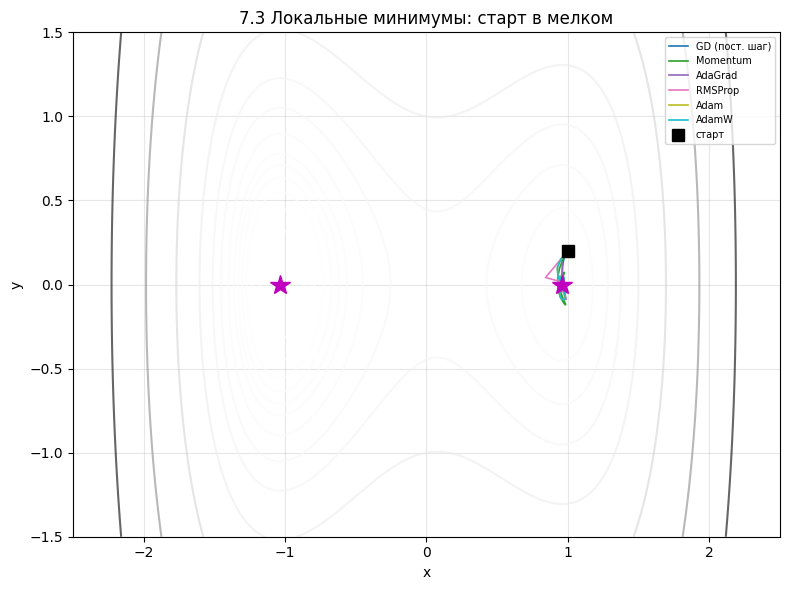

In [14]:
def f_mm(x):
    return (x[0]**2 - 1)**2 + 0.3*x[0] + x[1]**2

def grad_mm(x, t):
    return [4*x[0]*(x[0]**2 - 1) + 0.3, 2*x[1]]

ETA_M = 0.05
N_M = 4000

# найдём локальные минимумы по оси x (y = 0) сканированием
xs_scan = linspace(-2.0, 2.0, 400)
vals = [f_mm([x, 0.0]) for x in xs_scan]
mins = [xs_scan[i] for i in range(1, len(xs_scan) - 1)
        if vals[i] < vals[i-1] and vals[i] < vals[i+1]]

lines = ["| Метод | Финальная точка | f | Бассейн |", "|:---|:---:|:---:|:---|"]
mm_hist = {}
for method, label in METHODS:
    h = run_dynamic(method, grad_mm, [1.0, 0.2], ETA_M, N_M)
    mm_hist[method] = h
    xf, yf = h[-1]
    basin = "глубокий (слева)" if xf < 0 else "мелкий (справа)"
    lines.append(f"| {label} | ({xf:.3f}; {yf:.3f}) | {f_mm(h[-1]):.4f} | {basin} |")
display(Markdown("\n".join(lines)))
print("локальные минимумы по x:", [f"{m:.3f}" for m in mins])

xs = linspace(-2.5, 2.5, 250); ys = linspace(-1.5, 1.5, 200)
X, Y = meshgrid(xs, ys)
Z = [[f_mm([x, y]) for x in xs] for y in ys]
MM_LEVELS = [-0.2, -0.1, 0.0, 0.1, 0.2, 0.3, 0.5, 0.8, 1.2, 2.0, 4.0, 8.0, 15.0]
plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z, levels=MM_LEVELS, cmap="Greys", alpha=0.6)
colors = plt.cm.tab10([i / (len(METHODS) - 1) for i in range(len(METHODS))])
for (method, label), color in zip(METHODS, colors):
    h = mm_hist[method]
    plt.plot([p[0] for p in h], [p[1] for p in h], "-", color=color, lw=1.2, label=label)
for m in mins:
    plt.plot(m, 0, "m*", ms=15)
plt.plot(1.0, 0.2, "ks", ms=8, label="старт")
plt.xlim(-2.5, 2.5); plt.ylim(-1.5, 1.5)
plt.xlabel("x"); plt.ylabel("y")
plt.title("7.3 Локальные минимумы: старт в мелком")
plt.legend(fontsize=7); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

#### 7.3.1. То же, но с шумом

Добавим тот же гауссов шум `σ = 1.0`, что и в 7.1, и сделаем по 20 запусков на метод.
Смотрим, кто вообще выбирается из мелкой ямы в глубокую.

| Метод | У глубокого минимума | Средний f (последние 200 шагов) |
|:---|:---:|:---:|
| GD (пост. шаг) | 0/20 | 0.323 |
| Momentum | 11/20 | 0.087 |
| AdaGrad | 0/20 | 0.294 |
| RMSProp | 0/20 | 0.321 |
| Adam | 0/20 | 0.318 |
| AdamW | 0/20 | 0.318 |

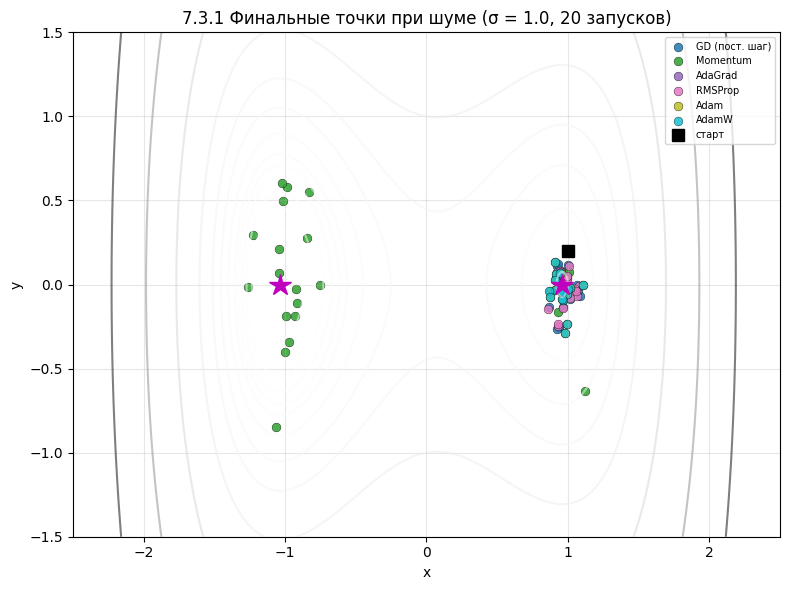

In [15]:
DEEP = [-1.038, 0.0]
SIGMA_MM = 1.0
S_MM = 20
N_MM = 4000

lines = ["| Метод | У глубокого минимума | Средний f (последние 200 шагов) |", "|:---|:---:|:---:|"]
final_pts = {}
for method, label in METHODS:
    pts = []
    near_cnt = 0
    fvals = []
    for seed in range(S_MM):
        h = run_dynamic(method, grad_mm, [1.0, 0.2], 0.05, N_MM, noise=SIGMA_MM, seed=seed)
        pts.append(h[-1])
        if dist(h[-1], DEEP) < 0.4:
            near_cnt += 1
        tail = h[-200:]
        fvals.append(sum(f_mm(p) for p in tail) / len(tail))
    final_pts[method] = pts
    lines.append(f"| {label} | {near_cnt}/{S_MM} | {sum(fvals)/len(fvals):.3f} |")
display(Markdown("\n".join(lines)))

xs = linspace(-2.5, 2.5, 250); ys = linspace(-1.5, 1.5, 200)
X, Y = meshgrid(xs, ys)
Z = [[f_mm([x, y]) for x in xs] for y in ys]
plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z, levels=MM_LEVELS, cmap="Greys", alpha=0.5)
colors = plt.cm.tab10([i / (len(METHODS) - 1) for i in range(len(METHODS))])
for (method, label), color in zip(METHODS, colors):
    pts = final_pts[method]
    plt.scatter([p[0] for p in pts], [p[1] for p in pts],
                s=40, color=color, label=label, alpha=0.85, edgecolors="k", linewidths=0.3)
for m in mins:
    plt.plot(m, 0, "m*", ms=16)
plt.plot(1.0, 0.2, "ks", ms=8, label="старт")
plt.xlim(-2.5, 2.5); plt.ylim(-1.5, 1.5)
plt.xlabel("x"); plt.ylabel("y")
plt.title("7.3.1 Финальные точки при шуме (σ = 1.0, 20 запусков)")
plt.legend(fontsize=7); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

Таким образом при наличии шума "выбирается" из мелкого минимума и попадает в глубокий, когда остальные методы остаются в мелком. Таким образом в ряде случаев шум может помогать выбиратсья из локальных минимумов. 

### 7.4. Плато + узкая яма

`f = y² + 0.0005·x² − 2·exp(−(x−2)²/0.05)`: слева — почти **плоское плато**, справа — **глубокая,
но очень узкая** яма. Momentum разгоняется и проскакивает её; адаптивные успевают затормозить.

| Метод | Финальный x | f | Куда пришёл |
|:---|:---:|:---:|:---|
| GD (пост. шаг) | 4.390 | 0.0096 | не дошёл |
| Momentum | 0.003 | 0.0000 | мелкая яма (x≈0) |
| AdaGrad | 2.000 | -1.9980 | глубокая яма (x≈2) |
| RMSProp | 1.950 | -1.8979 | глубокая яма (x≈2) |
| Adam | 2.000 | -1.9980 | глубокая яма (x≈2) |
| AdamW | 2.001 | -1.9980 | глубокая яма (x≈2) |

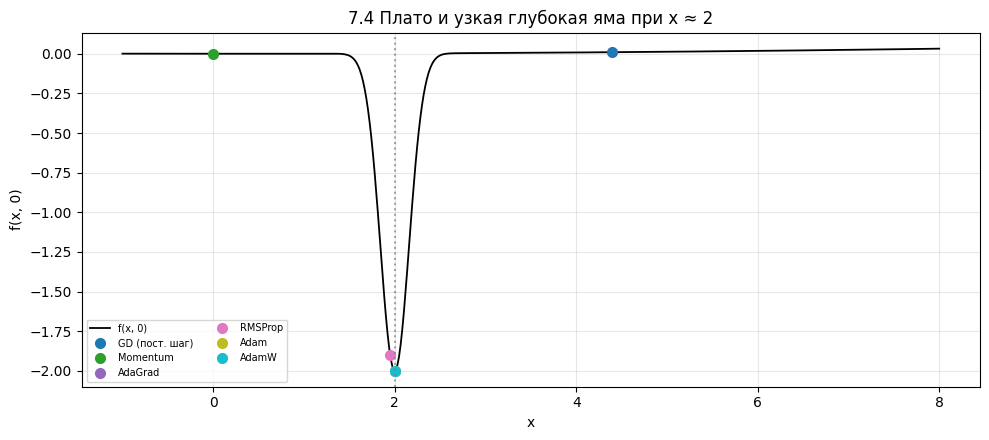

In [16]:
def f_pl(x):
    return x[1]**2 + 0.0005*x[0]**2 - 2.0*math.exp(-((x[0] - 2.0)**2)/0.05)

def grad_pl(x, t):
    gx = 0.001*x[0] + 4.0*(x[0] - 2.0)/0.05 * math.exp(-((x[0] - 2.0)**2)/0.05)
    return [gx, 2*x[1]]

ETA_P = 0.1
N_P = 6000

lines = ["| Метод | Финальный x | f | Куда пришёл |", "|:---|:---:|:---:|:---|"]
pl_hist = {}
for method, label in METHODS:
    h = run_dynamic(method, grad_pl, [8.0, 0.5], ETA_P, N_P)
    pl_hist[method] = h
    xf = h[-1][0]
    where = "глубокая яма (x≈2)" if abs(xf - 2.0) < 0.6 else ("мелкая яма (x≈0)" if abs(xf) < 0.6 else "не дошёл")
    lines.append(f"| {label} | {xf:.3f} | {f_pl(h[-1]):.4f} | {where} |")
display(Markdown("\n".join(lines)))

xs = linspace(-1.0, 8.0, 500)
Vs = [f_pl([x, 0.0]) for x in xs]
plt.figure(figsize=(10, 4.5))
plt.plot(xs, Vs, "k-", lw=1.3, label="f(x, 0)")
colors = plt.cm.tab10([i / (len(METHODS) - 1) for i in range(len(METHODS))])
for (method, label), color in zip(METHODS, colors):
    xf = pl_hist[method][-1][0]
    plt.plot(xf, f_pl([xf, 0.0]), "o", color=color, ms=7, label=label)
plt.axvline(2.0, color="gray", ls=":", alpha=0.7)
plt.xlabel("x"); plt.ylabel("f(x, 0)")
plt.title("7.4 Плато и узкая глубокая яма при x ≈ 2")
plt.legend(fontsize=7, ncol=2); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Вывод:** На плато градиенты близки к нулю. GD не доходит до ямы. Momentum перескакивает через яму. Остальные методы эффективно достигают дна

### Вывод по нестандартным случаям

Таким образом можно сделать вывод, что для простых задач любой метод работает, и использование более сложных методов может быть излишним. Однако для сложных функций адаптивные методы (Adam/AdamW) предпочтительнее ввиду их большей устойчивости к размеру шага и характеру функции.


## 8. Общий вывод

GD эффективен только на простых функциях.

Momentum: Добавляет инерцию, за счет чего уменьшает загзаги в оврагах и помогает проскакивать седловые точки, но может проскакивать минимум при высоком значении шага.

AdaGrad: Адаптирует шаг для каждого параметра. В задачах с постоянными большими градиентами (Розенброк) шаг обучения преждевременно стремится к нулю, и обучение останавливается.

RMSProp: Улучшенная версия AdaGrad. Справляется с оврагами (Розенброк, МНК) и показывает высокую устойчивость к выбору размера шага. 

Adam: Комбинирует преимущества Momentum (инерция) и RMSProp (адаптивный шаг). Устойчив к выбору размера шага, справляется с большинством тестов и показывает универсальность применения на разных функциях. 

AdamW: Модификация Adam с "weight decay" (разделенным затуханием весов). В данных задачах его траектория и количество шагов практически идентичны Adam. 